# 05 · Advanced Customer Analysis: Value, Satisfaction & Delivery

**Project:** Olist E-Commerce Customer Segmentation & Retention Analysis  
**Pipeline:** Notebook 5 of 5 · Previous ← [04 · RFM & K-Means Segmentation](04_rfm_and_kmeans_segmentation.ipynb)

## Purpose
Builds on the four K-Means segments to answer business questions:
1. How much historical value does each segment represent?
2. How satisfied is each segment (review scores and sentiment)?
3. How does delivery performance affect satisfaction?
4. Which retention actions fit each segment?

| | |
|---|---|
| **Input** | `olist_customer_segments.csv` (Notebook 04) · `order_reviews_no_header.csv` (Notebook 02) · `olist_orders_dataset.csv` · `olist_customers_dataset.csv` |
| **Output** | 8 summary CSVs (satisfaction, sentiment, delivery impact, value, business insights, recommendations) |
| **Libraries** | pandas, numpy, matplotlib, seaborn |
| **Environment** | Google Colab |

> **How to run:** execute the cells in order. The input files must be present in `/content/` (upload them or mount Google Drive).

**Note:** "customer value" in this notebook is **historical product spending** (R$), not a predicted lifetime value.

## 1. Load the Customer Segments

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load customer segmentation data
customers = pd.read_csv('/content/olist_customer_segments.csv')

# Display dataset information
print("Dataset Shape:", customers.shape)
print("\nFirst 5 Rows:")
display(customers.head())

print("\nDataset Information:")
customers.info()

Dataset Shape: (93358, 6)

First 5 Rows:


,customer_unique_id,recency,frequency,monetary,cluster,cluster_name
0,0000366f3b9a7992bf8c76cfdf3221e2,111,1,129.90,3,Recent High-Spenders
1,0000b849f77a49e4a4ce2b2a4ca5be3f,114,1,18.90,0,Recent Low-Spenders
2,0000f46a3911fa3c0805444483337064,537,1,69.00,1,Hibernating Customers
3,0000f6ccb0745a6a4b88665a16c9f078,321,1,25.99,0,Recent Low-Spenders
4,0004aac84e0df4da2b147fca70cf8255,288,1,180.00,3,Recent High-Spenders



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 93358 entries, 0 to 93357
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_unique_id  93358 non-null  object 
 1   recency             93358 non-null  int64  
 2   frequency           93358 non-null  int64  
 3   monetary            93358 non-null  float64
 4   cluster             93358 non-null  int64  
 5   cluster_name        93358 non-null  object 
dtypes: float64(1), int64(3), object(2)
memory usage: 4.3+ MB


## 2. Customer Value by Segment

In [2]:
# Customer value analysis by segment

clv_summary = customers.groupby('cluster_name').agg(
    customer_count=('customer_unique_id', 'nunique'),
    total_customer_value=('monetary', 'sum'),
    average_customer_value=('monetary', 'mean'),
    median_customer_value=('monetary', 'median'),
    average_frequency=('frequency', 'mean')
).reset_index()

# Calculate revenue contribution
clv_summary['revenue_contribution_%'] = (
    clv_summary['total_customer_value']
    / customers['monetary'].sum()
) * 100

# Sort by total customer value
clv_summary = clv_summary.sort_values(
    by='total_customer_value',
    ascending=False
)

display(clv_summary.round(2))

,cluster_name,customer_count,total_customer_value,average_customer_value,median_customer_value,average_frequency,revenue_contribution_%
1,Recent High-Spenders,32369,8128784.92,251.13,159.0,1.00,61.48
0,Hibernating Customers,27189,2988101.65,109.90,82.0,1.00,22.60
2,Recent Low-Spenders,30999,1376202.79,44.40,43.5,1.00,10.41
3,Repeat Buyers,2801,728408.75,260.05,182.1,2.11,5.51


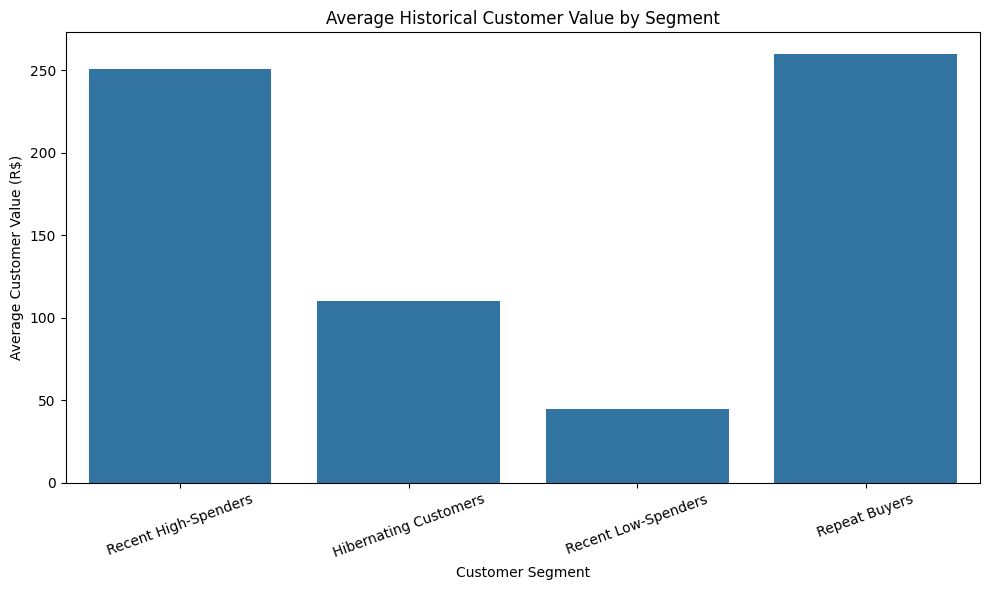

In [3]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=clv_summary,
    x='cluster_name',
    y='average_customer_value'
)

plt.title('Average Historical Customer Value by Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Average Customer Value (R$)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

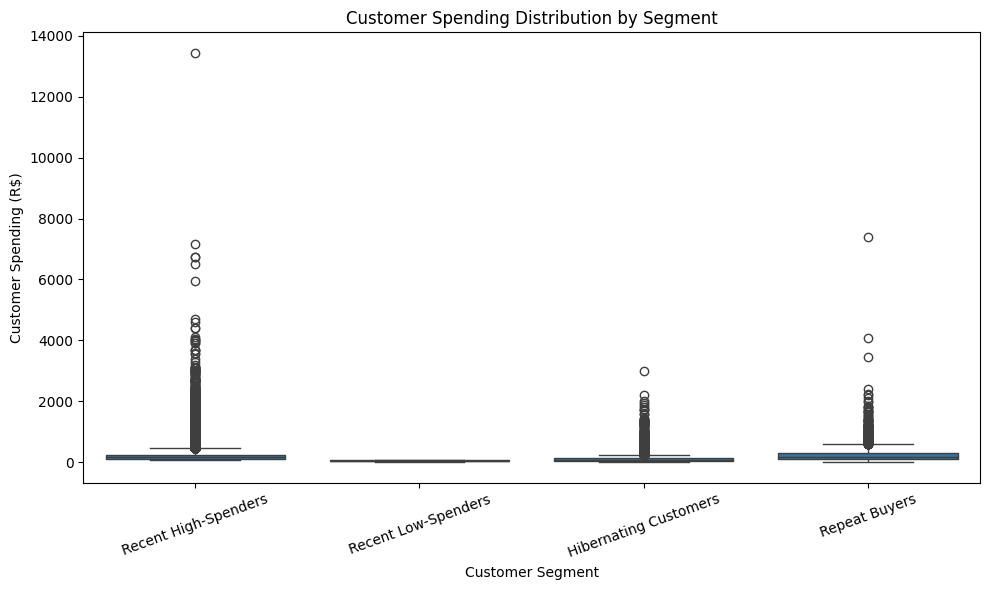

In [4]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=customers,
    x='cluster_name',
    y='monetary'
)

plt.title('Customer Spending Distribution by Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Customer Spending (R$)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [5]:
# Calculate the 90th percentile of customer spending
high_value_threshold = customers['monetary'].quantile(0.90)

# Filter high-value customers
high_value_customers = customers[
    customers['monetary'] >= high_value_threshold
]

print("High-Value Customer Threshold: R$", round(high_value_threshold, 2))
print("Number of High-Value Customers:", len(high_value_customers))

print("\nHigh-Value Customers by Segment:")
display(
    high_value_customers['cluster_name']
    .value_counts()
    .reset_index()
    .rename(columns={
        'cluster_name': 'Customer Segment',
        'count': 'Customer Count'
    })
)

High-Value Customer Threshold: R$ 279.99
Number of High-Value Customers: 9357

High-Value Customers by Segment:


,Customer Segment,Customer Count
0,Recent High-Spenders,7110
1,Hibernating Customers,1443
2,Repeat Buyers,804


#### Findings: Customer value
- **Recent High-Spenders** (32,369 customers) account for R$8.13M, **61.48%** of total customer value, with an average of R$251.13 (median R$159).
- **Repeat Buyers** are only 2,801 customers (5.51% of value) but have the **highest average value (R$260.05)** and average 2.11 orders.
- **Hibernating Customers** contribute 22.60% of value; **Recent Low-Spenders** contribute 10.41% with an average of only R$44.40.
- The top 10% of customers by spend start at **R$279.99** (9,357 customers): 7,110 are Recent High-Spenders, 1,443 Hibernating and 804 Repeat Buyers. None are Recent Low-Spenders.

## 3. Customer Satisfaction by Segment
Review scores are linked to segments through orders and customers.

### 3.1 Load and prepare the reviews, orders and customers

In [6]:
reviews = pd.read_csv(
    '/content/order_reviews_no_header.csv',
    header=None
)

print("Dataset Shape:", reviews.shape)
display(reviews.head())

Dataset Shape: (99224, 7)


,0,1,2,3,4,5,6
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [7]:
reviews.columns = [
    'review_id',
    'order_id',
    'review_score',
    'review_comment_title',
    'review_comment_message',
    'review_creation_date',
    'review_answer_timestamp'
]

# Convert date columns
reviews['review_creation_date'] = pd.to_datetime(
    reviews['review_creation_date']
)

reviews['review_answer_timestamp'] = pd.to_datetime(
    reviews['review_answer_timestamp']
)

print("Updated Dataset Shape:", reviews.shape)
print("\nColumn Names:")
print(reviews.columns.tolist())

print("\nReview Score Distribution:")
display(reviews['review_score'].value_counts().sort_index())

Updated Dataset Shape: (99224, 7)

Column Names:
['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']

Review Score Distribution:


,count
review_score,
1,11424
2,3151
3,8179
4,19142
5,57328


In [8]:
orders = pd.read_csv(
    '/content/olist_orders_dataset.csv',
    header=None
)

orders.head()

,0,1,2,3,4,5,6,7
0,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
1,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
2,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
3,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
4,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00


In [9]:
orders.columns = orders.iloc[0]
orders = orders.iloc[1:].reset_index(drop=True)

print("Updated Shape:", orders.shape)
print("\nColumn Names:")
print(orders.columns.tolist())

orders.head()

Updated Shape: (99441, 8)

Column Names:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [10]:
customers_data = pd.read_csv(
    '/content/olist_customers_dataset.csv',
    header=None
)

customers_data.head()

,0,1,2,3,4
0,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
1,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
2,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,09790,sao bernardo do campo,SP
3,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,01151,sao paulo,SP
4,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,08775,mogi das cruzes,SP


In [11]:
customers_data.columns = customers_data.iloc[0]
customers_data = customers_data.iloc[1:].reset_index(drop=True)

print("Updated Shape:", customers_data.shape)
print("\nColumn Names:")
print(customers_data.columns.tolist())

customers_data.head()

Updated Shape: (99441, 5)

Column Names:
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,09790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,01151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,08775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


### 3.2 Link reviews to customer segments

In [12]:
reviews_with_customers = reviews.merge(
    orders[['order_id', 'customer_id']],
    on='order_id',
    how='left'
)

reviews_with_customers = reviews_with_customers.merge(
    customers_data[['customer_id', 'customer_unique_id']],
    on='customer_id',
    how='left'
)

print("Merged Shape:", reviews_with_customers.shape)
print("\nMissing Customer IDs:",
      reviews_with_customers['customer_unique_id'].isna().sum())

reviews_with_customers.head()

Merged Shape: (99224, 9)

Missing Customer IDs: 0


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,customer_id,customer_unique_id
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18,2018-01-18 21:46:59,41dcb106f807e993532d446263290104,68a5590b9926689be4e10f4ae2db21a8
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10,2018-03-11 03:05:13,8a2e7ef9053dea531e4dc76bd6d853e6,64190b91b656ab8f37eb89b93dc84584
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17,2018-02-18 14:36:24,e226dfed6544df5b7b87a48208690feb,1d47144362c14e94ccdd213e8ec277d5
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21,2017-04-21 22:02:06,de6dff97e5f1ba84a3cd9a3bc97df5f6,c8cf6cb6b838dc7a33ed199b825e8616
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01,2018-03-02 10:26:53,5986b333ca0d44534a156a52a8e33a83,d16000272660a1fef81482ad75ba572a


In [13]:
reviews_with_segments = reviews_with_customers.merge(
    customers[['customer_unique_id', 'cluster_name']],
    on='customer_unique_id',
    how='inner'
)

print("Final Shape:", reviews_with_segments.shape)
print("\nMissing Segments:",
      reviews_with_segments['cluster_name'].isna().sum())

reviews_with_segments.head()

Final Shape: (96572, 10)

Missing Segments: 0


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,customer_id,customer_unique_id,cluster_name
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18,2018-01-18 21:46:59,41dcb106f807e993532d446263290104,68a5590b9926689be4e10f4ae2db21a8,Recent High-Spenders
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10,2018-03-11 03:05:13,8a2e7ef9053dea531e4dc76bd6d853e6,64190b91b656ab8f37eb89b93dc84584,Recent Low-Spenders
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17,2018-02-18 14:36:24,e226dfed6544df5b7b87a48208690feb,1d47144362c14e94ccdd213e8ec277d5,Recent High-Spenders
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21,2017-04-21 22:02:06,de6dff97e5f1ba84a3cd9a3bc97df5f6,c8cf6cb6b838dc7a33ed199b825e8616,Hibernating Customers
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01,2018-03-02 10:26:53,5986b333ca0d44534a156a52a8e33a83,d16000272660a1fef81482ad75ba572a,Recent High-Spenders


In [14]:
customer_satisfaction = reviews_with_segments.groupby(
    ['customer_unique_id', 'cluster_name']
).agg(
    average_review_score=('review_score', 'mean'),
    review_count=('review_score', 'count')
).reset_index()

print("Unique Customers Reviewed:",
      customer_satisfaction['customer_unique_id'].nunique())

customer_satisfaction.head()

Unique Customers Reviewed: 92755


,customer_unique_id,cluster_name,average_review_score,review_count
0,0000366f3b9a7992bf8c76cfdf3221e2,Recent High-Spenders,5.0,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,Recent Low-Spenders,4.0,1
2,0000f46a3911fa3c0805444483337064,Hibernating Customers,3.0,1
3,0000f6ccb0745a6a4b88665a16c9f078,Recent Low-Spenders,4.0,1
4,0004aac84e0df4da2b147fca70cf8255,Recent High-Spenders,5.0,1


Reviews are matched to segments with an inner join, so reviews from customers outside the segmentation (which is based on delivered orders) are dropped: 96,572 of 99,224 reviews remain, covering 92,755 customers.

### 3.3 Satisfaction metrics

In [15]:
segment_satisfaction = customer_satisfaction.groupby(
    'cluster_name'
).agg(
    customer_count=('customer_unique_id', 'nunique'),
    average_satisfaction=('average_review_score', 'mean'),
    total_reviews=('review_count', 'sum')
).reset_index()

segment_satisfaction = segment_satisfaction.sort_values(
    by='average_satisfaction',
    ascending=False
)

display(segment_satisfaction.round(2))

,cluster_name,customer_count,average_satisfaction,total_reviews
0,Hibernating Customers,26992,4.22,27100
3,Repeat Buyers,2792,4.20,6332
2,Recent Low-Spenders,30820,4.18,30912
1,Recent High-Spenders,32151,4.07,32228


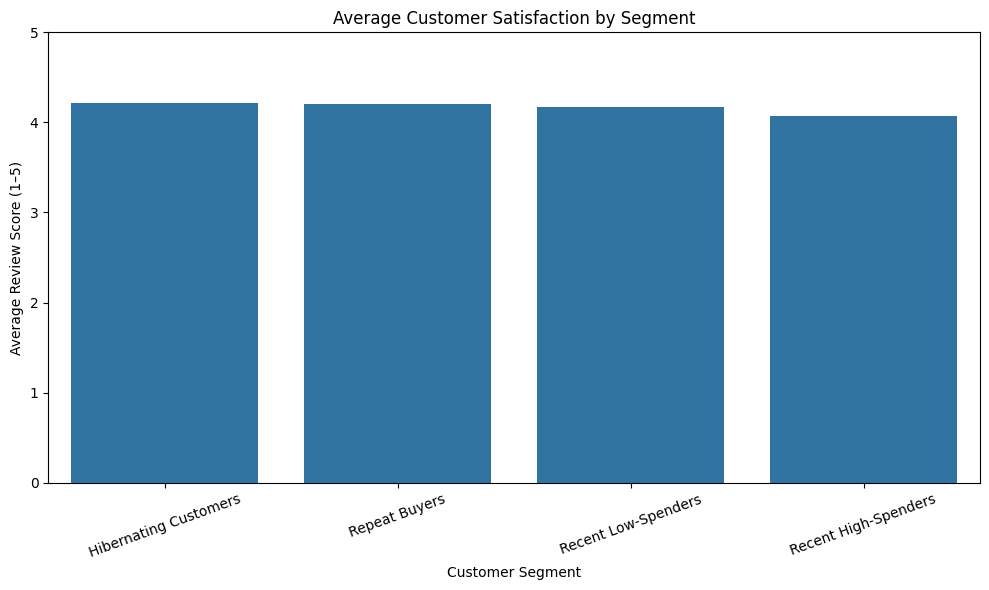

In [16]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=segment_satisfaction,
    x='cluster_name',
    y='average_satisfaction'
)

plt.title('Average Customer Satisfaction by Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Average Review Score (1–5)')
plt.ylim(0, 5)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

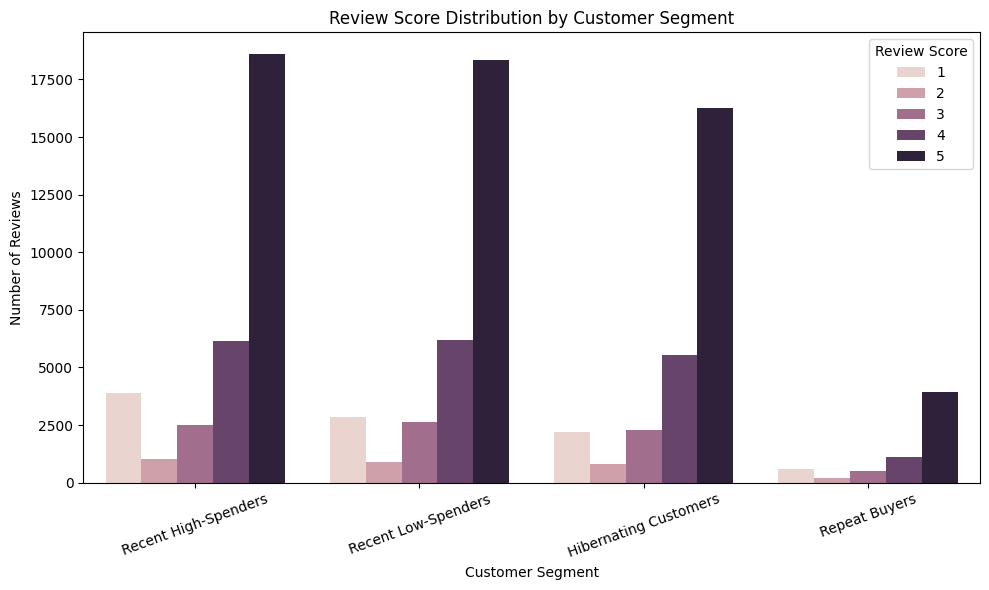

In [17]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=reviews_with_segments,
    x='cluster_name',
    hue='review_score'
)

plt.title('Review Score Distribution by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=20)
plt.legend(title='Review Score')
plt.tight_layout()
plt.show()

In [18]:
segment_satisfaction['negative_review_rate_%'] = (
    reviews_with_segments.assign(
        is_negative=reviews_with_segments['review_score'].isin([1, 2])
    )
    .groupby('cluster_name')['is_negative']
    .mean()
    .reindex(segment_satisfaction['cluster_name'])
    .values * 100
)

display(segment_satisfaction.round(2))

,cluster_name,customer_count,average_satisfaction,total_reviews,negative_review_rate_%
0,Hibernating Customers,26992,4.22,27100,11.07
3,Repeat Buyers,2792,4.20,6332,12.05
2,Recent Low-Spenders,30820,4.18,30912,12.17
1,Recent High-Spenders,32151,4.07,32228,15.36


In [20]:
segment_satisfaction.to_csv(
    'olist_segment_satisfaction.csv',
    index=False
)

print("Satisfaction analysis exported successfully!")

Satisfaction analysis exported successfully!


#### Findings: Satisfaction
- Reviews are strongly positive overall: 57,328 of 99,224 (about 58%) are 5-star, while 11,424 are 1-star.
- **Hibernating Customers are the most satisfied** (average 4.22; 11.07% negative reviews).
- **Recent High-Spenders are the least satisfied** (average 4.07) and have the **highest negative-review rate (15.36%)**, even though they are the most valuable segment.

| Segment | Avg review score | Negative reviews (1–2 stars) |
|---|---:|---:|
| Hibernating Customers | 4.22 | 11.07% |
| Repeat Buyers | 4.20 | 12.05% |
| Recent Low-Spenders | 4.18 | 12.17% |
| Recent High-Spenders | 4.07 | 15.36% |

## 4. Delivery Performance vs Satisfaction
Delivery delay = actual delivery date minus estimated delivery date (negative = earlier than promised).

In [21]:
delivery_analysis = orders[
    ['order_id', 'order_delivered_customer_date',
     'order_estimated_delivery_date']
].copy()

delivery_analysis['order_delivered_customer_date'] = pd.to_datetime(
    delivery_analysis['order_delivered_customer_date'],
    errors='coerce'
)

delivery_analysis['order_estimated_delivery_date'] = pd.to_datetime(
    delivery_analysis['order_estimated_delivery_date'],
    errors='coerce'
)

delivery_analysis = delivery_analysis.dropna(
    subset=[
        'order_delivered_customer_date',
        'order_estimated_delivery_date'
    ]
)

delivery_analysis['delivery_delay_days'] = (
    delivery_analysis['order_delivered_customer_date'].dt.normalize()
    - delivery_analysis['order_estimated_delivery_date'].dt.normalize()
).dt.days

print("Delivery Records:", len(delivery_analysis))
print("\nDelivery Delay Summary:")
display(delivery_analysis['delivery_delay_days'].describe().round(2))

Delivery Records: 96476

Delivery Delay Summary:


,delivery_delay_days
count,96476.00
mean,-11.88
std,10.18
min,-147.00
25%,-17.00
50%,-12.00
75%,-7.00
max,188.00


In [23]:
delivery_analysis['delivery_status'] = np.select(
    [
        delivery_analysis['delivery_delay_days'] < 0,
        delivery_analysis['delivery_delay_days'] == 0,
        delivery_analysis['delivery_delay_days'] > 0
    ],
    [
        'Early',
        'On-Time',
        'Late'
    ],
    default='Unknown'
)

print("Delivery Status Distribution:")
display(
    delivery_analysis['delivery_status']
    .value_counts()
    .to_frame('order_count')
)

print("\nDelivery Status Percentage:")
display(
    (delivery_analysis['delivery_status']
     .value_counts(normalize=True) * 100)
    .round(2)
    .to_frame('percentage')
)

Delivery Status Distribution:


,order_count
delivery_status,
Early,88649
Late,6535
On-Time,1292



Delivery Status Percentage:


,percentage
delivery_status,
Early,91.89
Late,6.77
On-Time,1.34


In [24]:
order_reviews = reviews_with_segments.groupby('order_id').agg(
    average_review_score=('review_score', 'mean'),
    cluster_name=('cluster_name', 'first')
).reset_index()

delivery_satisfaction = delivery_analysis.merge(
    order_reviews,
    on='order_id',
    how='inner'
)

print("Matched Orders:", len(delivery_satisfaction))

display(
    delivery_satisfaction.groupby('delivery_status').agg(
        order_count=('order_id', 'nunique'),
        average_satisfaction=('average_review_score', 'mean')
    ).round(2)
)

Matched Orders: 95824


,order_count,average_satisfaction
delivery_status,,
Early,88163,4.29
Late,6381,2.27
On-Time,1280,4.04


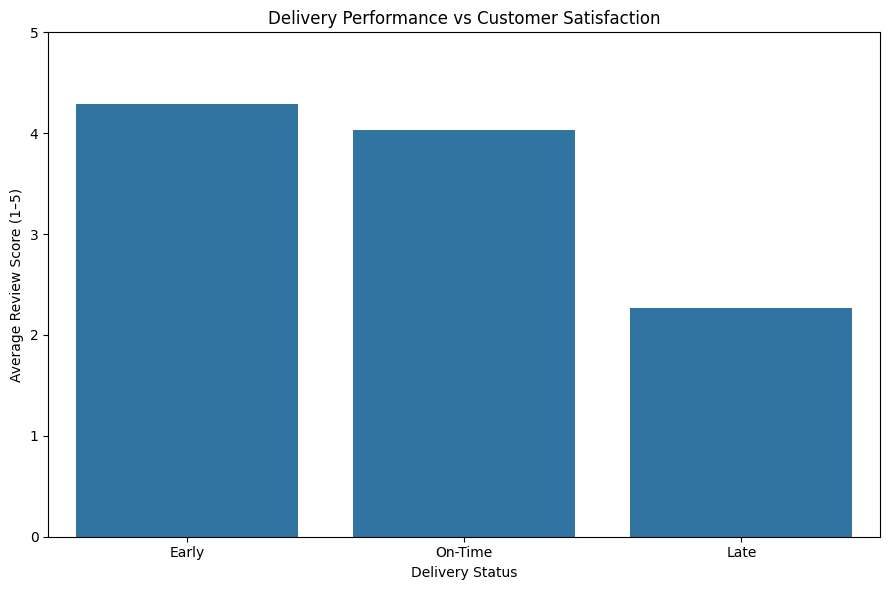

In [25]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=delivery_satisfaction.groupby('delivery_status')[
        'average_review_score'
    ].mean().reset_index(),
    x='delivery_status',
    y='average_review_score',
    order=['Early', 'On-Time', 'Late']
)

plt.title('Delivery Performance vs Customer Satisfaction')
plt.xlabel('Delivery Status')
plt.ylabel('Average Review Score (1–5)')
plt.ylim(0, 5)
plt.tight_layout()
plt.show()

In [26]:
delivery_satisfaction_summary = (
    delivery_satisfaction.groupby('delivery_status')
    .agg(
        order_count=('order_id', 'nunique'),
        average_satisfaction=('average_review_score', 'mean'),
        average_delay_days=('delivery_delay_days', 'mean')
    )
    .reset_index()
)

delivery_satisfaction_summary.to_csv(
    'olist_delivery_satisfaction.csv',
    index=False
)

print("Delivery satisfaction analysis exported successfully!")

display(delivery_satisfaction_summary.round(2))

Delivery satisfaction analysis exported successfully!


,delivery_status,order_count,average_satisfaction,average_delay_days
0,Early,88163,4.29,-13.71
1,Late,6381,2.27,10.52
2,On-Time,1280,4.04,0.00


In [27]:
late_delivery_by_segment = delivery_satisfaction[
    delivery_satisfaction['delivery_status'] == 'Late'
].groupby('cluster_name').agg(
    late_orders=('order_id', 'nunique'),
    average_satisfaction=('average_review_score', 'mean')
).reset_index()

late_delivery_by_segment = late_delivery_by_segment.sort_values(
    by='average_satisfaction'
)

display(late_delivery_by_segment.round(2))

,cluster_name,late_orders,average_satisfaction
1,Recent High-Spenders,2648,2.15
2,Recent Low-Spenders,2293,2.30
0,Hibernating Customers,1112,2.45
3,Repeat Buyers,328,2.47


In [28]:
late_delivery_by_segment.to_csv(
    'olist_late_delivery_by_segment.csv',
    index=False
)

print("Late delivery segment analysis exported successfully!")

Late delivery segment analysis exported successfully!


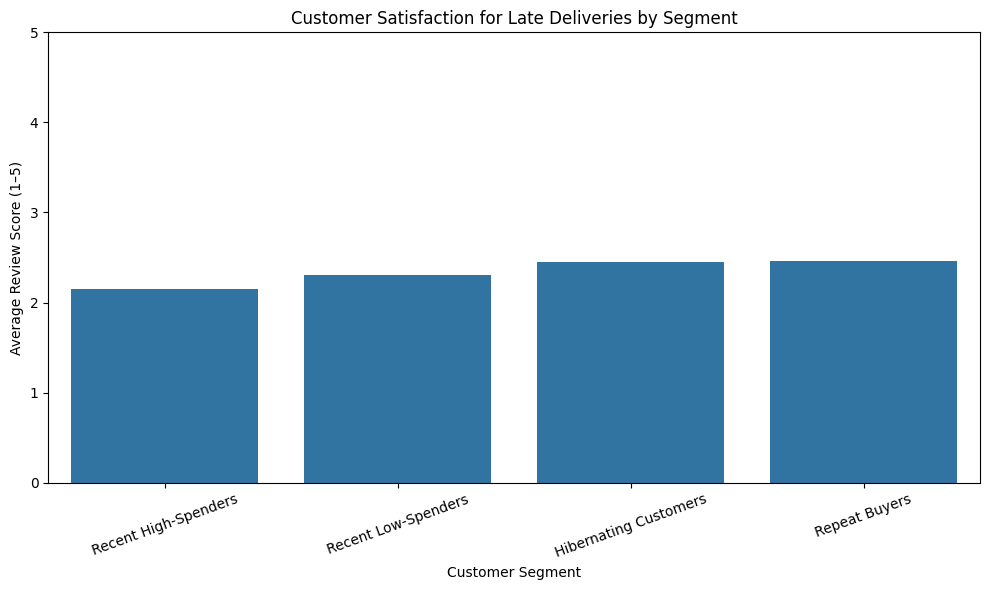

In [29]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=late_delivery_by_segment,
    x='cluster_name',
    y='average_satisfaction'
)

plt.title('Customer Satisfaction for Late Deliveries by Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Average Review Score (1–5)')
plt.ylim(0, 5)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

#### Findings: Delivery and satisfaction
- Across 96,476 delivered orders, **91.89% arrived early**, 1.34% on the estimated date and **6.77% late**. The median order arrived 12 days before the estimate.
- Satisfaction depends strongly on timing: **4.29** for early deliveries, 4.04 for on-time and just **2.27 for late deliveries**.
- Late deliveries lower satisfaction in every segment, and most for **Recent High-Spenders** (2.15, with the largest number of late orders, 2,648), compared with 2.30 (Recent Low-Spenders), 2.45 (Hibernating) and 2.47 (Repeat Buyers).

## 5. Review Sentiment by Segment
Scores 1–2 are classed as negative, 3 as neutral and 4–5 as positive.

In [31]:
reviews_with_segments['sentiment'] = np.select(
    [
        reviews_with_segments['review_score'].isin([1, 2]),
        reviews_with_segments['review_score'] == 3,
        reviews_with_segments['review_score'].isin([4, 5])
    ],
    [
        'Negative',
        'Neutral',
        'Positive'
    ],
    default='Unknown'
)

sentiment_by_segment = pd.crosstab(
    reviews_with_segments['cluster_name'],
    reviews_with_segments['sentiment'],
    normalize='index'
) * 100

display(sentiment_by_segment.round(2))

sentiment,Negative,Neutral,Positive
cluster_name,,,
Hibernating Customers,11.07,8.51,80.42
Recent High-Spenders,15.36,7.83,76.82
Recent Low-Spenders,12.17,8.51,79.32
Repeat Buyers,12.05,8.15,79.80


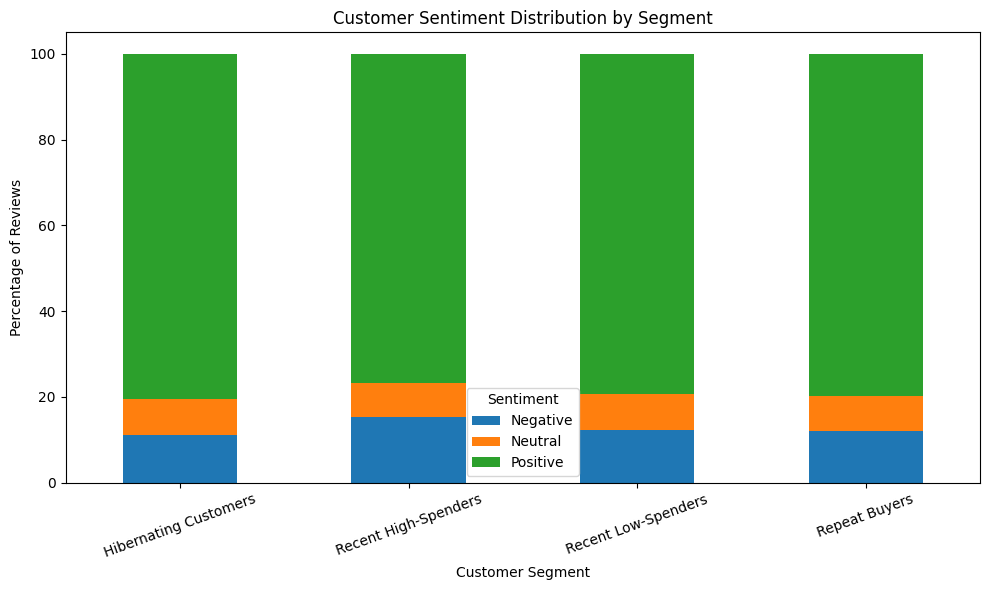

In [32]:
sentiment_by_segment.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title('Customer Sentiment Distribution by Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Percentage of Reviews')
plt.xticks(rotation=20)
plt.legend(title='Sentiment')
plt.tight_layout()
plt.show()

In [33]:
sentiment_by_segment.to_csv(
    'olist_segment_sentiment.csv'
)

print("Sentiment analysis exported successfully!")

Sentiment analysis exported successfully!


#### Findings: Sentiment
Positive reviews range from 76.82% (Recent High-Spenders) to 80.42% (Hibernating Customers). Recent High-Spenders have the highest share of negative reviews (15.36%) and the lowest share of neutral ones (7.83%).

## 6. Impact of Delivery Delay Severity
Delivery delay is grouped into five categories: *Very Early* (more than 7 days early), *Slightly Early* (1–7 days early), *On-Time*, *Slightly Late* (1–7 days late) and *Very Late* (more than 7 days late).

In [35]:
delivery_satisfaction['delay_category'] = np.select(
    [
        delivery_satisfaction['delivery_delay_days'] < -7,
        delivery_satisfaction['delivery_delay_days'].between(-7, -1),
        delivery_satisfaction['delivery_delay_days'] == 0,
        delivery_satisfaction['delivery_delay_days'].between(1, 7),
        delivery_satisfaction['delivery_delay_days'] > 7
    ],
    [
        'Very Early',
        'Slightly Early',
        'On-Time',
        'Slightly Late',
        'Very Late'
    ],
    default='Unknown'
)

delay_category_summary = delivery_satisfaction.groupby(
    'delay_category'
).agg(
    order_count=('order_id', 'nunique'),
    average_satisfaction=('average_review_score', 'mean')
).reset_index()

display(delay_category_summary.round(2))

,delay_category,order_count,average_satisfaction
0,On-Time,1280,4.04
1,Slightly Early,17234,4.20
2,Slightly Late,3600,2.72
3,Very Early,70929,4.32
4,Very Late,2781,1.70


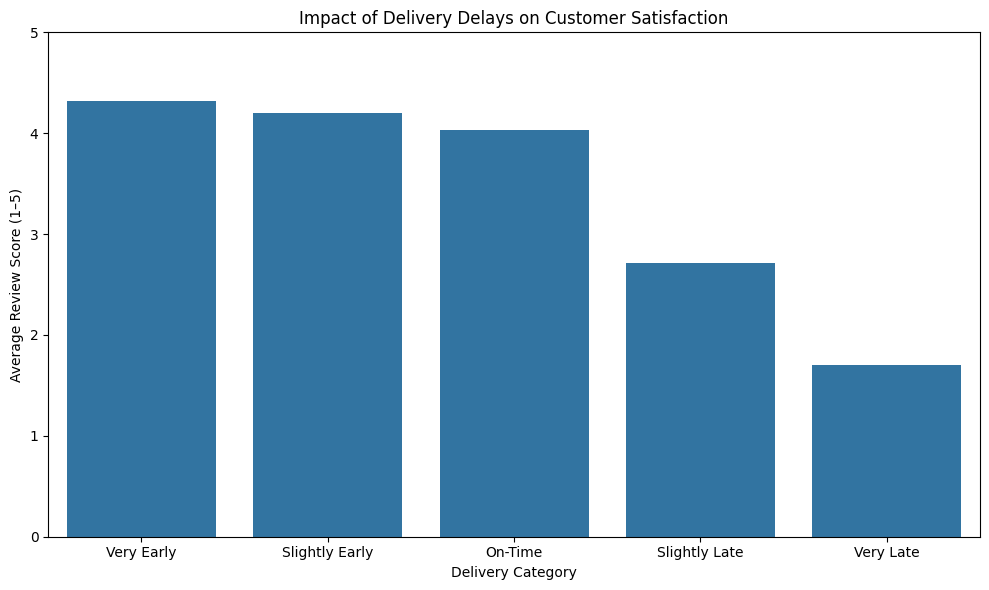

In [36]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=delay_category_summary,
    x='delay_category',
    y='average_satisfaction',
    order=[
        'Very Early',
        'Slightly Early',
        'On-Time',
        'Slightly Late',
        'Very Late'
    ]
)

plt.title('Impact of Delivery Delays on Customer Satisfaction')
plt.xlabel('Delivery Category')
plt.ylabel('Average Review Score (1–5)')
plt.ylim(0, 5)
plt.tight_layout()
plt.show()

In [37]:
delay_category_summary.to_csv(
    'olist_delivery_delay_impact.csv',
    index=False
)

print("Delivery delay impact analysis exported successfully!")

Delivery delay impact analysis exported successfully!


#### Findings: Delay severity
| Delivery category | Orders | Avg review score |
|---|---:|---:|
| Very Early | 70,929 | 4.32 |
| Slightly Early | 17,234 | 4.20 |
| On-Time | 1,280 | 4.04 |
| Slightly Late | 3,600 | 2.72 |
| Very Late | 2,781 | 1.70 |

Satisfaction falls sharply once an order is late and keeps falling with the length of the delay: a delivery more than 7 days late averages only 1.70 out of 5.

## 7. Combined Business Insights
Combines value, revenue share and satisfaction for each segment.

In [38]:
clv_summary.to_csv(
    'olist_customer_lifetime_value_analysis.csv',
    index=False
)

print("Historical customer value analysis exported successfully!")

Historical customer value analysis exported successfully!


In [39]:
business_insights = clv_summary[
    [
        'cluster_name',
        'customer_count',
        'average_customer_value',
        'revenue_contribution_%'
    ]
].merge(
    segment_satisfaction[
        [
            'cluster_name',
            'average_satisfaction',
            'negative_review_rate_%'
        ]
    ],
    on='cluster_name',
    how='left'
)

display(business_insights.round(2))

,cluster_name,customer_count,average_customer_value,revenue_contribution_%,average_satisfaction,negative_review_rate_%
0,Recent High-Spenders,32369,251.13,61.48,4.07,15.36
1,Hibernating Customers,27189,109.90,22.60,4.22,11.07
2,Recent Low-Spenders,30999,44.40,10.41,4.18,12.17
3,Repeat Buyers,2801,260.05,5.51,4.20,12.05


In [40]:
business_insights.to_csv(
    'olist_business_insights.csv',
    index=False
)

print("Business insights exported successfully!")

Business insights exported successfully!


#### Findings: Segment overview
| Segment | Customers | Avg value (R$) | Revenue share | Avg satisfaction | Negative reviews |
|---|---:|---:|---:|---:|---:|
| Recent High-Spenders | 32,369 | 251.13 | 61.48% | 4.07 | 15.36% |
| Hibernating Customers | 27,189 | 109.90 | 22.60% | 4.22 | 11.07% |
| Recent Low-Spenders | 30,999 | 44.40 | 10.41% | 4.18 | 12.17% |
| Repeat Buyers | 2,801 | 260.05 | 5.51% | 4.20 | 12.05% |

The segment that generates most of the revenue is also the least satisfied, which makes it the priority for protection.

## 8. Segment Recommendations

In [41]:
business_recommendations = pd.DataFrame({
    'customer_segment': [
        'Recent High-Spenders',
        'Hibernating Customers',
        'Recent Low-Spenders',
        'Repeat Buyers'
    ],
    'business_problem': [
        'Highest negative review rate',
        'Long period since last purchase',
        'Low average customer spending',
        'Small customer segment'
    ],
    'recommended_action': [
        'Improve delivery reliability and provide priority customer support',
        'Launch personalized re-engagement campaigns with targeted offers',
        'Use product recommendations, bundles and small purchase incentives',
        'Introduce loyalty rewards and exclusive benefits'
    ],
    'business_goal': [
        'Protect major revenue contributors and improve satisfaction',
        'Recover inactive customers and generate repeat purchases',
        'Increase average order value and customer spending',
        'Improve customer retention and purchase frequency'
    ]
})

display(business_recommendations)

,customer_segment,business_problem,recommended_action,business_goal
0,Recent High-Spenders,Highest negative review rate,Improve delivery reliability and provide prior...,Protect major revenue contributors and improve...
1,Hibernating Customers,Long period since last purchase,Launch personalized re-engagement campaigns wi...,Recover inactive customers and generate repeat...
2,Recent Low-Spenders,Low average customer spending,"Use product recommendations, bundles and small...",Increase average order value and customer spen...
3,Repeat Buyers,Small customer segment,Introduce loyalty rewards and exclusive benefits,Improve customer retention and purchase frequency


In [42]:
business_recommendations.to_csv(
    'olist_business_recommendations.csv',
    index=False
)

print("Business recommendations exported successfully!")

Business recommendations exported successfully!


## 9. Conclusion

In [43]:
project_conclusion = """
The Olist E-commerce Customer Segmentation and Retention Analysis
examined customer purchasing behaviour, historical customer value,
satisfaction, and delivery performance.

Using RFM analysis and K-Means clustering, customers were divided
into four segments: Recent High-Spenders, Hibernating Customers,
Recent Low-Spenders, and Repeat Buyers.

Recent High-Spenders contributed 61.48% of total customer revenue,
making them an important segment for business retention.
Repeat Buyers represented only 3% of customers but had the highest
average historical customer value of R$260.05.

Customer satisfaction analysis showed that Hibernating Customers
had the highest average satisfaction score of 4.22, while Recent
High-Spenders had the highest negative review rate of 15.36%.

Delivery analysis revealed a strong association between late
deliveries and lower customer satisfaction. Late deliveries had
an average review score of 2.27, compared with 4.29 for early
deliveries.

The analysis recommends personalized retention campaigns,
improved delivery reliability, targeted promotions, and loyalty
programs to improve customer experience and business performance.

Overall, this project demonstrates how Python, SQL, Machine Learning,
and Power BI can support data-driven e-commerce decisions.
"""

print(project_conclusion)


The Olist E-commerce Customer Segmentation and Retention Analysis
examined customer purchasing behaviour, historical customer value,
satisfaction, and delivery performance.

Using RFM analysis and K-Means clustering, customers were divided
into four segments: Recent High-Spenders, Hibernating Customers,
Recent Low-Spenders, and Repeat Buyers.

Recent High-Spenders contributed 61.48% of total customer revenue,
making them an important segment for business retention.
Repeat Buyers represented only 3% of customers but had the highest
average historical customer value of R$260.05.

Customer satisfaction analysis showed that Hibernating Customers
had the highest average satisfaction score of 4.22, while Recent
High-Spenders had the highest negative review rate of 15.36%.

Delivery analysis revealed a strong association between late
deliveries and lower customer satisfaction. Late deliveries had
an average review score of 2.27, compared with 4.29 for early
deliveries.

The analysis recommen